In [1]:
from cmath import sqrt

import pandas as pd

etfs = pd.read_csv('etf_prices.csv', index_col=0, parse_dates=True)
etfs.head()

,DBC,EEM,EFA,EWJ,GLD,HYG,IEF,IWM,LQD,QQQ,...,VNQ,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,,,,,,,,,,,,,
2008-01-02,26.991882,33.408070,44.837990,38.190758,84.860001,31.210020,55.187599,58.372108,51.199692,43.264091,...,28.255741,13.806764,22.269384,16.094007,26.864412,10.205407,17.147572,10.954020,25.242624,12.711695
2008-01-03,27.199957,33.708649,44.912514,38.335083,85.570000,31.150375,55.300961,57.727493,51.030785,43.444328,...,27.374914,14.057489,22.532700,15.991850,26.885344,10.221030,17.056969,10.938407,25.394342,12.569577
2008-01-04,27.041821,32.696144,43.892166,37.353622,85.129997,31.115900,55.445812,55.987812,51.450676,41.539032,...,26.263494,13.632918,21.709152,15.537856,26.334246,9.822507,16.984495,11.021687,25.134251,12.174801
2008-01-07,26.550756,32.935722,43.938023,37.122681,84.769997,30.930838,55.546589,56.112091,51.387947,41.341629,...,26.507923,13.445713,21.625109,15.577585,26.006371,9.736553,17.183807,11.250706,25.632742,12.218228
2008-01-08,26.792126,32.680317,43.691536,37.036087,86.779999,30.752043,55.666214,54.380180,51.291367,40.268826,...,25.590204,13.238447,21.246962,15.010090,25.427372,9.478681,17.056969,11.253309,25.842266,11.981367


In [2]:
#we investigate our data and look in to missing rows / values
date_gaps = etfs.index.to_series()
date_gaps = date_gaps.diff()
date_gaps

Date
2008-01-02      NaT
2008-01-03   1 days
2008-01-04   1 days
2008-01-07   3 days
2008-01-08   1 days
              ...  
2026-10-05   3 days
2026-10-06   1 days
2026-10-07   1 days
2026-10-08   1 days
2026-10-09   1 days
Name: Date, Length: 4723, dtype: timedelta64[us]

In [3]:
# Calculating returns
daily_returns = etfs.pct_change().iloc[1:]
daily_returns

,DBC,EEM,EFA,EWJ,GLD,HYG,IEF,IWM,LQD,QQQ,...,VNQ,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,,,,,,,,,,,,,
2008-01-03,0.007709,0.008997,0.001662,0.003779,0.008367,-0.001911,0.002054,-0.011043,-0.003299,0.004166,...,-0.031173,0.018160,0.011824,-0.006348,0.000779,0.001531,-0.005284,-0.001425,0.006010,-0.011180
2008-01-04,-0.005814,-0.030037,-0.022719,-0.025602,-0.005142,-0.001107,0.002619,-0.030136,0.008228,-0.043856,...,-0.040600,-0.030202,-0.036549,-0.028389,-0.020498,-0.038991,-0.004249,0.007614,-0.010242,-0.031407
2008-01-07,-0.018159,0.007327,0.001045,-0.006183,-0.004229,-0.005948,0.001818,0.002220,-0.001219,-0.004752,...,0.009307,-0.013732,-0.003871,0.002557,-0.012451,-0.008751,0.011735,0.020779,0.019833,0.003567
2008-01-08,0.009091,-0.007755,-0.005610,-0.002333,0.023711,-0.005780,0.002154,-0.030865,-0.001879,-0.025950,...,-0.034621,-0.015415,-0.017486,-0.036430,-0.022264,-0.026485,-0.007381,0.000231,0.008174,-0.019386
2008-01-09,-0.009941,0.032780,0.007216,0.021823,-0.002650,-0.010914,-0.001583,0.010140,-0.002070,0.021313,...,0.017660,0.006313,0.013183,0.018904,0.003017,0.014015,0.013456,0.010870,0.017892,0.007248
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-05,-0.004610,0.015664,0.000673,0.003842,-0.001552,0.000910,-0.001460,0.006607,0.000000,0.008832,...,-0.003911,0.013099,0.010029,0.007291,0.000883,0.005605,0.006333,0.003515,0.007161,0.003453
2026-10-06,0.009262,-0.006693,0.001826,0.000201,0.007166,0.003767,0.002362,-0.007199,0.003044,0.004575,...,0.008749,0.004646,0.004728,0.002413,0.008701,0.005325,0.009378,0.029772,-0.001673,0.011773
2026-10-07,-0.005506,-0.013183,-0.010747,-0.010068,-0.016716,-0.001165,-0.000224,-0.012938,-0.000392,-0.002541,...,-0.013788,-0.015081,-0.006118,-0.004814,-0.021797,-0.003020,-0.001223,-0.000243,0.010294,-0.003222


In [4]:
# Looking at data
daily_returns.shape

(4722, 27)

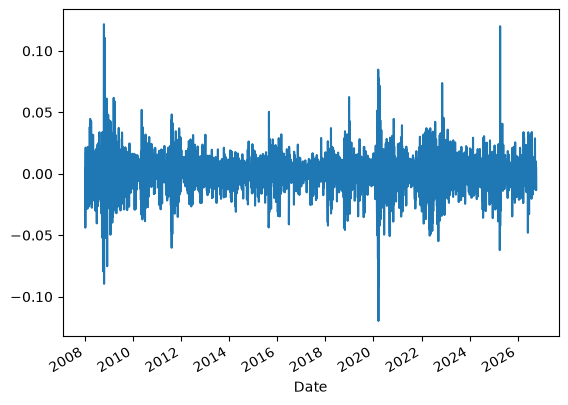

In [5]:
#number of rows seems about right (corresponding to 252*18.8 trading days
import matplotlib.pyplot as plt
daily_returns['QQQ'].plot()
plt.show()

In [6]:
# Average returns seem to be roughly 0 with major volatilty at certain periods. Volatility seems also to be increasing over time.
# Need to find missing values if there are any still, in our data.
daily_returns.isna().any()

DBC    False
EEM    False
EFA    False
EWJ    False
GLD    False
HYG    False
IEF    False
IWM    False
LQD    False
QQQ    False
SHY    False
SLV    False
SPY    False
TIP    False
TLT    False
USO    False
VGK    False
VNQ    False
XLB    False
XLE    False
XLF    False
XLI    False
XLK    False
XLP    False
XLU    False
XLV    False
XLY    False
dtype: bool

In [7]:
#Number of 0 days per asset
(daily_returns==0).sum()

DBC     82
EEM     34
EFA     36
EWJ     95
GLD     13
HYG     69
IEF     38
IWM      9
LQD     48
QQQ     20
SHY    417
SLV     80
SPY     12
TIP     69
TLT     19
USO     30
VGK     28
VNQ     23
XLB     43
XLE     21
XLF     67
XLI     33
XLK     46
XLP     71
XLU     48
XLV     48
XLY     33
dtype: int64

In [8]:
# All look ok except SHY which seems suspicious. Let's have a look at the asset more closely.

In [9]:
#What are our 0 return days
zero_return_dates = daily_returns[daily_returns['SHY'] == 0].index
date_diffs = zero_return_dates.to_series().diff()
consecutive_dates = zero_return_dates[date_diffs == pd.Timedelta(days=1)]
print(consecutive_dates)

DatetimeIndex(['2011-07-19', '2011-12-13', '2012-03-06', '2012-04-17',
               '2012-07-10', '2012-08-21', '2012-10-04', '2012-11-09',
               '2012-11-16', '2012-12-07', '2012-12-11', '2013-01-24',
               '2013-04-10', '2013-04-11', '2013-04-17', '2013-04-18',
               '2013-04-19', '2013-05-07', '2013-06-18', '2013-09-13',
               '2013-10-11', '2013-10-30', '2014-08-05', '2014-08-12',
               '2014-08-19', '2017-03-24', '2017-07-20', '2018-05-11',
               '2018-05-22', '2018-07-31', '2019-02-05', '2020-08-20',
               '2020-10-09', '2020-10-28', '2020-12-16', '2020-12-22',
               '2021-03-05', '2021-05-28', '2021-08-19', '2021-08-20',
               '2021-09-03'],
              dtype='datetime64[us]', name='Date', freq=None)


In [10]:
# Let's check for clustezero_return_dates = daily_returns[daily_returns['SHY'] == 0].index
zero_return_all = daily_returns.eq(0).all(axis=1)
dates_all_zero = daily_returns.index[zero_return_all]
print(dates_all_zero)


DatetimeIndex([], dtype='datetime64[us]', name='Date', freq=None)


In [11]:
# Let's look at max, min and volatility across asset classes. We expect SHY to come out as comparatively low.
max_returns = daily_returns.max()
min_returns = daily_returns.min()
volatility = daily_returns.std(ddof=0)

analysed_returns = pd.concat([max_returns, min_returns, volatility], axis=1)
analysed_returns.columns = ['max_return', 'min_return', 'volatility']
analysed_returns

,max_return,min_return,volatility
DBC,0.068744,-0.079444,0.012209
EEM,0.227699,-0.161662,0.017452
EFA,0.158876,-0.111632,0.013687
EWJ,0.158220,-0.104077,0.013077
GLD,0.112905,-0.102742,0.011473
HYG,0.122689,-0.080974,0.006853
IEF,0.034263,-0.025073,0.004384
IWM,0.091491,-0.132669,0.015586
LQD,0.097676,-0.091111,0.005595
QQQ,0.121647,-0.119788,0.014098


In [12]:
# We can confirm that SHY has the lowest comparative volatility.
# Let's have a look at the sample covariance matrix S of selected assests between 2009 - 2011
columns = ['DBC', 'GLD','HYG', 'QQQ', 'SHY', 'TLT', 'XLB','XLE', 'XLI', 'XLU', 'XLY']

sample_returns = daily_returns[columns].loc['2009-01-01':'2010-12-31',:]


sample_returns.shape

(504, 11)

In [13]:
# Solid T to N ratio.
T, N = sample_returns.shape
S = sample_returns.cov(ddof=0) # As Ledoit and Wolf use for large T
S

,DBC,GLD,HYG,QQQ,SHY,TLT,XLB,XLE,XLI,XLU,XLY
DBC,0.000223,0.000063,0.000069,0.000123,-3.789658e-06,-0.000053,0.000192,0.000210,0.000160,0.000088,0.000145
GLD,0.000063,0.000140,-0.000002,0.000012,1.805207e-06,0.000013,0.000054,0.000035,0.000018,0.000011,0.000011
HYG,0.000069,-0.000002,0.000088,0.000086,-1.778101e-06,-0.000033,0.000112,0.000113,0.000115,0.000056,0.000105
QQQ,0.000123,0.000012,0.000086,0.000203,-4.782557e-06,-0.000064,0.000223,0.000220,0.000221,0.000109,0.000218
SHY,-0.000004,0.000002,-0.000002,-0.000005,9.577524e-07,0.000007,-0.000005,-0.000007,-0.000006,-0.000003,-0.000006
TLT,-0.000053,0.000013,-0.000033,-0.000064,6.861230e-06,0.000120,-0.000072,-0.000084,-0.000073,-0.000043,-0.000071
XLB,0.000192,0.000054,0.000112,0.000223,-5.331446e-06,-0.000072,0.000347,0.000304,0.000283,0.000142,0.000262
XLE,0.000210,0.000035,0.000113,0.000220,-6.562566e-06,-0.000084,0.000304,0.000353,0.000278,0.000154,0.000255
XLI,0.000160,0.000018,0.000115,0.000221,-5.975877e-06,-0.000073,0.000283,0.000278,0.000309,0.000138,0.000268
XLU,0.000088,0.000011,0.000056,0.000109,-3.174984e-06,-0.000043,0.000142,0.000154,0.000138,0.000126,0.000127


In [14]:
# Sample correlation matrix
import numpy as np
sample_corr = sample_returns.corr()

# Average pairwise correlation
n = len(sample_corr)
rbar = sample_corr.values[np.triu_indices(n, k=1)].mean()

# Sample variances
variances = sample_returns.var(ddof=0).values
std_devs = np.sqrt(variances)

# Construct F
F = rbar * np.outer(std_devs, std_devs)
np.fill_diagonal(F, variances)


In [15]:
# Calculating delta using formulas provided in papers
S =S.to_numpy()

In [16]:
Y = sample_returns.to_numpy()
Y_bar = Y.mean(axis=0)
S.shape

(11, 11)

In [17]:
Y_bar = Y.mean(axis=0)

# Deviations from the column means
Y_centered = Y - Y_bar

# Calculate pi estimator
pi_hat = np.sum(
    (Y_centered[:, :, None] * Y_centered[:, None, :] - S) ** 2
) / T

In [18]:
# Calculate rho estimator
# Products of demeaned returns
products = (
    Y_centered[:, :, None]
    * Y_centered[:, None, :]
)

# First factor: (Y_ti - Y_bar_i)^2 - s_ii
squared_deviations = Y_centered**2 - np.diag(S)

# Second factor: (Y_ti - Y_bar_i)(Y_tj - Y_bar_j) - s_ij
covariance_deviations = products - S

# Estimate theta_hat_ii,ij
theta_ii_ij = np.mean(
    squared_deviations[:, :, None] * covariance_deviations,
    axis=0
)

# Estimate theta_hat_jj,ij
theta_jj_ij = np.mean(
    squared_deviations[:, None, :] * covariance_deviations,
    axis=0
)

In [19]:
print(np.mean((Y_centered[:, :, None] * Y_centered[:, None, :] - S)**2, axis=0).shape)

(11, 11)


In [20]:
# rho estimator
variances = np.diag(S)

# Ratios of variances, with [i, j] = s_jj / s_ii
ratio = np.sqrt(variances[None, :] / variances[:, None])

# Terms inside the double sum
terms = rbar / 2 * (
    ratio * theta_ii_ij
    + (1 / ratio) * theta_jj_ij
)

# Exclude diagonal terms (i == j)
np.fill_diagonal(terms, 0)

pi_hat_diag = np.diag(
    np.mean(
        (Y_centered[:, :, None] * Y_centered[:, None, :] - S)**2, axis=0))

rho_hat = pi_hat_diag.sum() + terms.sum()
rho_hat.shape

()

In [21]:
# Calculating gamma estimator
gamma_hat = np.sum((F-S)**2)
gamma_hat.shape

()

In [22]:
# Calculating kappa estimator
kappa_hat = (pi_hat - rho_hat) / gamma_hat

In [23]:
# Making sure we arrive at one single variable
kappa_hat.shape

()

In [24]:
# Finally, shrinkage intensity delta_star
delta_star = max(0, min(kappa_hat/T, 1))
delta_star

np.float64(0.016722421873806046)

In [25]:
S_hat = delta_star * F + (1- delta_star) * S
S.shape

(11, 11)

In [26]:
# Before using the quadratic optimiser we need to forecast alpha while keeping the IR constant.
# Using sample returns.tail() we can see the last day in sample is 2010-12-31
# We'll use one month as the horizon - since all out calculations have been daily thus far - we will need to rescale by sqrt(21) in many cases
out_sample = etfs[columns].loc['2010-12-31':'2011-01-31',:]
realised_excess = out_sample.loc['2011-01-31'] - out_sample.loc['2010-12-31']

jan11_returns = realised_excess / out_sample.loc['2010-12-31']
jan11_normalised_excess_returns = jan11_returns - jan11_returns.mean()
jan11_normalised_excess_returns

DBC    0.026036
GLD   -0.073333
HYG    0.006966
QQQ    0.018741
SHY   -0.008226
TLT   -0.040347
XLB   -0.008755
XLE    0.062259
XLI    0.029753
XLU    0.002589
XLY   -0.015683
dtype: float64

In [77]:
#For forecasting alpha we will follow the steps in the paper Appendix C (Grinold-Kahn: alpha = volatility * IC * score)
# Seed is part of the experiment definition - it must be set BEFORE any draw
rng = np.random.default_rng(7)

# with an IR = 1.5, by the fundamental law of active management IC = IR / sqrt(breadth), breadth = 12 rebalances * N assets
IR = 1.5
IC = IR / np.sqrt(12*N)

# Monthly residual (active vs equal-weighted) volatility per ETF.
# .sub(..., axis=0) subtracts each day's cross-sectional mean from that day's row
active_daily = sample_returns.sub(sample_returns.mean(axis=1), axis=0)
s_e = np.sqrt(21) * active_daily.std(ddof=0)

# Step 1: Raw forecasts = realised active return + noise, with N independent draws scaled by each ETF's volatility.
# Noise size chosen so corr(raw / s_e, e / s_e) is roughly IC
e = jan11_normalised_excess_returns
u = s_e * np.sqrt(1 / IC**2 - 1) * rng.standard_normal(N)
raw = e + u

# Step 2: Scores - standardise in volatility units, then cross-sectionally to mean 0, std 1
z = raw / s_e
scores = (z - z.mean()) / z.std(ddof=0)

# Step 3: Refined forecasts (monthly)
alpha_forecast = s_e * IC * scores

# Check: with ddof=0 scores, sum(scores**2) = N, so the ex-ante IR sqrt(12 * sum((alpha / s_e)**2)) equals IR by construction
ex_ante_IR = np.sqrt(12 * ((alpha_forecast / s_e)**2).sum())
assert np.isclose(ex_ante_IR, IR), ex_ante_IR

In [78]:
alpha_forecast

DBC    0.001794
GLD    0.003053
HYG   -0.000755
QQQ   -0.004351
SHY   -0.003095
TLT   -0.013849
XLB    0.001501
XLE    0.015506
XLI   -0.002307
XLU   -0.003145
XLY    0.004577
dtype: float64

In [79]:
import cvxpy as cp
# Benchmark is equal-weighted; x is the active weight vector relative to it
wb = np.array([1/N for i in range(N)])
c = 0.15 # (assuming N > 10)
ones = np.ones(N)
alpha = alpha_forecast.to_numpy()

# Long-only, max weight c, fully invested (active weights sum to 0)
def weight_constraints(x):
    return [x @ ones == 0, x >= -wb, x <= c * ones - wb]

# The original g = 0.03 (3% a month) is infeasible: alpha is only ~0.1-1.5% per asset.
# Find the largest forecast active return the constraints allow, then target half of it
x = cp.Variable(N)
g_max = cp.Problem(cp.Maximize(x @ alpha), weight_constraints(x)).solve()
g = 0.5 * g_max
print('max achievable forecast alpha:', g_max, ' target g:', g)

max achievable forecast alpha: 0.0037180748170577557  target g: 0.0018590374085288778


In [80]:
# Minimum tracking variance subject to hitting the alpha target, solved once with S and once with S_hat
def optimal_active_weights(Sigma):
    x = cp.Variable(N)
    constraints = weight_constraints(x) + [x @ alpha >= g]
    prob = cp.Problem(cp.Minimize(cp.quad_form(x, Sigma)), constraints)
    prob.solve()
    assert prob.status == cp.OPTIMAL, prob.status
    return x.value

x_S = optimal_active_weights(S)
x_S_hat = optimal_active_weights(S_hat)

weights = pd.DataFrame({
    'active (S)': x_S,
    'active (S_hat)': x_S_hat,
    'difference': x_S_hat - x_S,
    'total (S)': wb + x_S,
    'total (S_hat)': wb + x_S_hat,
}, index=columns)
weights.round(4)

,active (S),active (S_hat),difference,total (S),total (S_hat)
DBC,-0.0235,-0.0232,0.0004,0.0674,0.0678
GLD,0.0191,0.0198,0.0007,0.1100,0.1107
HYG,0.0037,0.0037,0.0000,0.0946,0.0946
QQQ,-0.0623,-0.0604,0.0020,0.0286,0.0306
SHY,0.0428,0.0441,0.0012,0.1337,0.1350
TLT,-0.0285,-0.0304,-0.0018,0.0624,0.0605
XLB,-0.0141,-0.0139,0.0002,0.0768,0.0770
XLE,0.0591,0.0591,0.0000,0.1500,0.1500
XLI,-0.0328,-0.0313,0.0015,0.0581,0.0596
XLU,-0.0225,-0.0233,-0.0008,0.0685,0.0676


In [81]:
# Compare the two portfolios over January 2011.
# S and S_hat are daily, so ex-ante monthly tracking error is sqrt(21 * x'Sigma x).
# Realised active return is buy-and-hold from the 2010-12-31 close; since sum(x) = 0, x @ e = x @ r.
# Realised tracking error uses the 20 daily active returns in January, scaled by sqrt(21) - very noisy with one month of data.
jan11_daily = daily_returns[columns].loc['2011-01-01':'2011-01-31']

def summarise(x):
    return pd.Series({
        'forecast alpha': x @ alpha,
        'ex-ante TE under S': np.sqrt(21 * x @ S @ x),
        'ex-ante TE under S_hat': np.sqrt(21 * x @ S_hat @ x),
        'realised active return': x @ e.to_numpy(),
        'realised TE': np.sqrt(21) * (jan11_daily.to_numpy() @ x).std(ddof=0),
        'sum |active weights|': np.abs(x).sum(),
    })

comparison = pd.DataFrame({'S': summarise(x_S), 'S_hat': summarise(x_S_hat)})
comparison['S_hat - S'] = comparison['S_hat'] - comparison['S']
print('delta_star =', delta_star, ' sum |x_S_hat - x_S| =', np.abs(x_S_hat - x_S).sum())
comparison

delta_star = 0.016722421873806046  sum |x_S_hat - x_S| = 0.01196379103526406


,S,S_hat,S_hat - S
forecast alpha,0.001859,0.001859,0.000000
ex-ante TE under S,0.002871,0.002875,0.000004
ex-ante TE under S_hat,0.003004,0.003001,-0.000003
realised active return,-0.000515,-0.000364,0.000152
realised TE,0.002585,0.002643,0.000058
sum |active weights|,0.367548,0.364833,-0.002715


In [32]:
# With T/N ~ 46 the shrinkage intensity is only ~1.7%, so S_hat is almost S and the two portfolios are nearly identical
# (weights differ by ~1.2% in total). Both hit the same forecast alpha by construction; their ex-ante and realised
# tracking errors agree to within a few basis points, and both realised a small negative active return this month.
# One month with one noise draw cannot separate the estimators - that needs many months, smaller T/N and repeated draws.